In [ ]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from skimage import color, img_as_ubyte, io
from skimage.feature import graycomatrix, graycoprops, hog, local_binary_pattern
from skimage.transform import resize
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [37]:
warnings.filterwarnings("ignore")

In [38]:
DATASET_DIR = "dataset"
IMG_SIZE = (256, 256)
LEVELS = 64
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
DISTANCE = 1
PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
LOCAL_BINARY_PATTERN = {"P": 8, "R": 1, "method": "uniform"}
PIXEL_PER_CELL = (16, 16)
CELL_PER_BLOCK = (2, 2)

In [ ]:
PARAMS_SVM = {
    "C": 1.0,
    "kernel": "linear",
    "gamma": "scale",
    "class_weight": "balanced",
    "probability": True,
    "random_state": 42,
}

PARAMS_LOGISTIC_REGRESSION = {
    "C": 1.0,
    "penalty": "l2",
    "solver": "lbfgs",
    "class_weight": "balanced",
    "max_iter": 1000,
    "random_state": 42,
}

PARAMS_PCA = {
    "n_components": 0.95,
    "random_state": 42,
}

In [40]:
def extract_features(path):
    img = io.imread(path)
    img = resize(img, IMG_SIZE, anti_aliasing=True)
    if img.ndim == 3:
        img = color.rgb2gray(img)
    gray = img_as_ubyte(img)

    quantized = np.clip((gray.astype(np.uint16) * LEVELS) // 256, 0, LEVELS - 1).astype(np.uint8)
    glcm = graycomatrix(
        quantized,
        distances=[DISTANCE],
        angles=ANGLES,
        levels=LEVELS,
        symmetric=True,
        normed=True,
    )
    glcm_feat = np.concatenate([graycoprops(glcm, prop).ravel() for prop in PROPS])

    lbp = local_binary_pattern(gray, **LOCAL_BINARY_PATTERN)
    n_bins = LOCAL_BINARY_PATTERN["P"] + 2
    lbp_feat, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)

    hog_feat = hog(
        gray,
        pixels_per_cell=PIXEL_PER_CELL,
        cells_per_block=CELL_PER_BLOCK,
        feature_vector=True,
    )
    return np.concatenate([glcm_feat, lbp_feat, hog_feat])


records = []
labels = []

for grade in sorted(os.listdir(DATASET_DIR)):
    grade_dir = os.path.join(DATASET_DIR, grade)
    if not os.path.isdir(grade_dir):
        continue
    files = sorted(f for f in os.listdir(grade_dir) if f.endswith(".jpg"))
    for file in files:
        records.append(extract_features(os.path.join(grade_dir, file)))
        labels.append(grade)
    print(f"{grade}: {len(files)} images")

X = np.vstack(records)
Y = np.array(labels)
print(f"Total images processed: {len(Y)}")
print(f"Feature matrix: {X.shape}")

grade_a: 326 images
grade_b: 274 images
grade_c: 304 images
grade_reject: 96 images
Total images processed: 1000
Feature matrix: (1000, 8134)


In [41]:
df_test = pd.DataFrame(Y, columns=["label"])
df_train = pd.DataFrame(X, columns=[f"feature_{i}" for i in range(X.shape[1])])

In [42]:
df = pd.DataFrame(
    np.concatenate([df_train, df_test], axis=1),
    columns=[f"feature_{i}" for i in range(X.shape[1])] + ["label"],
)

In [43]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Columns: 8135 entries, feature_0 to label
dtypes: object(8134), str(1)
memory usage: 62.1+ MB


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_8125,feature_8126,feature_8127,feature_8128,feature_8129,feature_8130,feature_8131,feature_8132,feature_8133,label
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,...,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000
unique,998.000000,1000.000000,1000.000000,1000.000000,999.000000,999.000000,998.000000,999.000000,1000.000000,1000.000000,...,996.0,558.0,989.0,737.0,997.0,849.0,993.0,770.0,156.0,4
top,0.768719,1.352787,1.165074,1.441722,0.362117,0.398247,0.312071,0.380592,0.912891,0.859801,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,grade_a
freq,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,...,5.0,443.0,12.0,264.0,4.0,152.0,8.0,231.0,845.0,326


In [44]:
df["label"].unique()
df["label"].value_counts()

label
grade_a         326
grade_c         304
grade_b         274
grade_reject     96
Name: count, dtype: int64

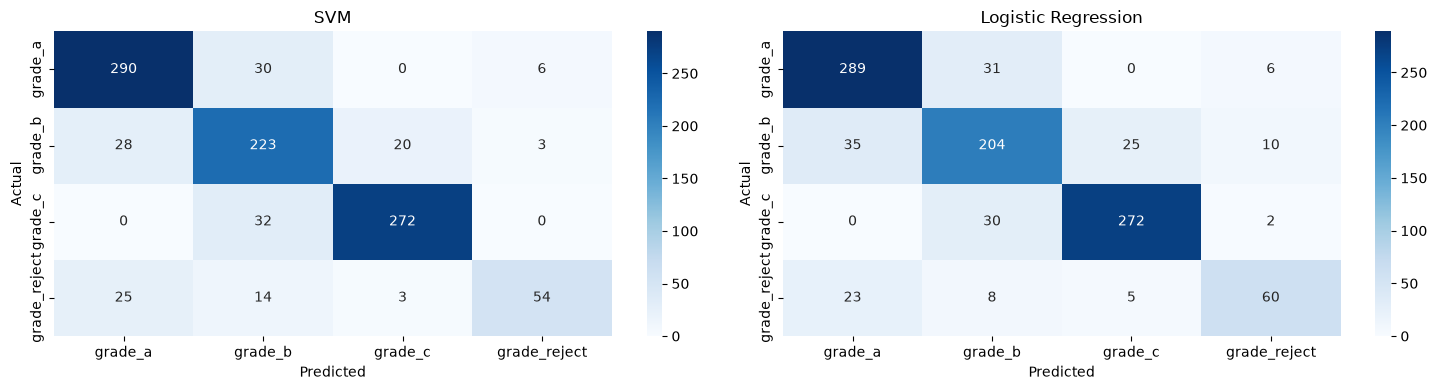

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,ROC_AUC_OVR_Macro
0,SVM,0.839,0.842619,0.790169,0.808188,0.959768
1,Logistic Regression,0.825,0.812500,0.787691,0.798018,0.954343


Model terbaik berdasarkan macro-F1: SVM


In [ ]:
categorical_labels = pd.Categorical(df_test["label"])
labels = pd.Series(categorical_labels.codes)
class_names = categorical_labels.categories.tolist()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "SVM": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", PCA(**PARAMS_PCA)),
            ("model", SVC(**PARAMS_SVM)),
        ]
    ),
    "Logistic Regression": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("pca", PCA(**PARAMS_PCA)),
            (
                "model",
                LogisticRegression(**PARAMS_LOGISTIC_REGRESSION),
            ),
        ]
    ),
}

results = []
plt.figure(figsize=(15, 4))

for index, (name, model) in enumerate(models.items(), start=1):
    y_pred = cross_val_predict(model, df_train, labels, cv=skf, method="predict", n_jobs=-1)
    y_score = cross_val_predict(model, df_train, labels, cv=skf, method="predict_proba", n_jobs=-1)

    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(labels, y_pred),
            "Precision_Macro": precision_score(labels, y_pred, average="macro", zero_division=0),
            "Recall_Macro": recall_score(labels, y_pred, average="macro", zero_division=0),
            "F1_Macro": f1_score(labels, y_pred, average="macro", zero_division=0),
            "ROC_AUC_OVR_Macro": roc_auc_score(labels, y_score, multi_class="ovr", average="macro"),
        }
    )

    cm = confusion_matrix(labels, y_pred)
    plt.subplot(1, len(models), index)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names
    )
    plt.title(name)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

plt.tight_layout()
plt.show()
results_df = pd.DataFrame(results).sort_values("F1_Macro", ascending=False)
display(results_df)
print(f"Model terbaik berdasarkan macro-F1: {results_df.iloc[0]['Model']}")